In [2]:
import pandas as pd
import polars as pl
import os
import torch
import pairadigm
import dotenv

dotenv.load_dotenv(dotenv_path='/fs/clip-projects/clip-k12/mlchrzan/.env')

/nfshomes/mlchrzan/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [19]:
# Load Data and Pairadigms
emobank = pd.read_csv('Data/emobank.csv')
emopair = pd.read_csv('Results/emopair.csv')
emopair_pairs = pd.read_csv("Results/emopair_pairs.csv")
validation_valence = pairadigm.load_pairadigm("Results/pairadigms/untied_valence_pairadigm_12-19-25.pkl")
validation_arousal = pairadigm.load_pairadigm("Results/pairadigms/untied_arousal_pairadigm_12-19-25.pkl")
validation_dominance = pairadigm.load_pairadigm("Results/pairadigms/untied_dominance_pairadigm_12-19-25.pkl")

# Load final BT scores/EMOPAIR data 
emopair = pd.read_csv('Results/emopair.csv')

Pairadigm object loaded successfully from: Results/pairadigms/untied_valence_pairadigm_12-19-25.pkl
Pairadigm object loaded successfully from: Results/pairadigms/untied_arousal_pairadigm_12-19-25.pkl
Pairadigm object loaded successfully from: Results/pairadigms/untied_dominance_pairadigm_12-19-25.pkl
Pairadigm object loaded successfully from: Results/pairadigms/emopair_aro_untied.pkl
Pairadigm object loaded successfully from: Results/pairadigms/emopair_dom_untied.pkl


# Annotator Validation

In [ ]:
altest_results = []
for construct in ['valence', 'arousal', 'dominance']:
    if construct == 'valence':
        _ , data = validation_valence.plot_epsilon_sensitivity(return_data=True);
    elif construct == 'dominance':
        _ , data = validation_dominance.plot_epsilon_sensitivity(return_data=True);
    elif construct == 'arousal':
        _ , data = validation_arousal.plot_epsilon_sensitivity(return_data=True);
    data['construct'] = construct
    altest_results.append(data)
    
altest_results = pd.concat(altest_results, ignore_index=True)
altest_results.sort_values(by=['construct', 'model', 'epsilon'], inplace=True)
altest_results

In [5]:
altest_results

,epsilon,winning_rate,advantage_prob,model,construct
147,-0.10,0.0,0.765,claude-haiku-4-5,arousal
151,-0.09,0.0,0.765,claude-haiku-4-5,arousal
155,-0.08,0.0,0.765,claude-haiku-4-5,arousal
159,-0.07,0.0,0.765,claude-haiku-4-5,arousal
163,-0.06,0.0,0.765,claude-haiku-4-5,arousal
...,...,...,...,...,...
124,0.21,0.0,0.595,gpt-5.1,valence
128,0.22,0.0,0.595,gpt-5.1,valence
132,0.23,0.0,0.595,gpt-5.1,valence
136,0.24,0.0,0.595,gpt-5.1,valence


In [6]:
# Since advantage probability doesn't change with episilon, we can just take the first value for each model and construct
ad_probs = altest_results.groupby(['construct', 'model']).first().reset_index()[['construct', 'model', 'advantage_prob']].copy()
ad_probs

,construct,model,advantage_prob
0,arousal,claude-haiku-4-5,0.765000
1,arousal,claude-sonnet-4-5,0.840000
2,arousal,gpt-5-nano,0.820000
3,arousal,gpt-5.1,0.885000
4,dominance,claude-haiku-4-5,0.850000
5,dominance,claude-sonnet-4-5,0.880000
6,dominance,gpt-5-nano,0.830000
7,dominance,gpt-5.1,0.850000
8,valence,claude-haiku-4-5,0.566327
9,valence,claude-sonnet-4-5,0.535000


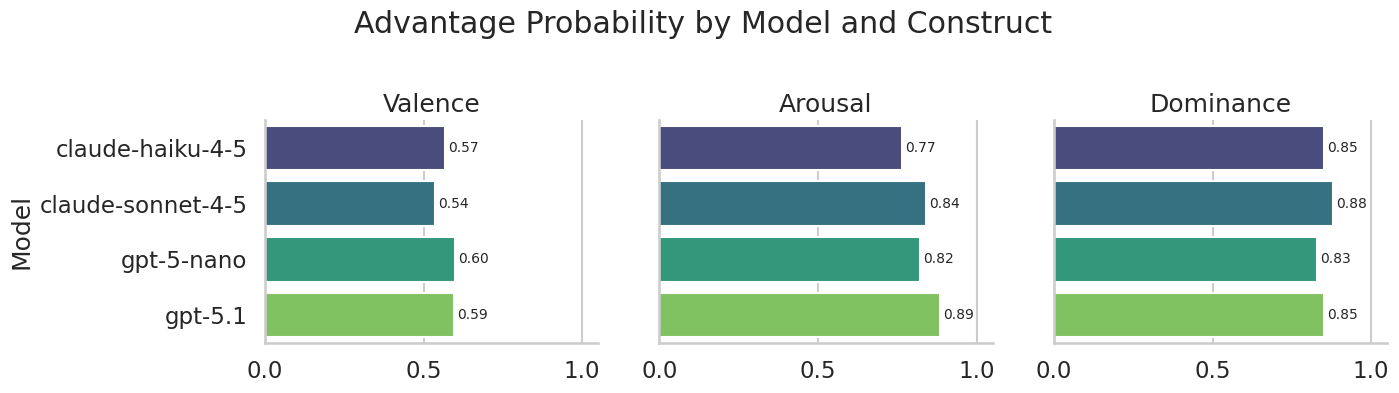

In [7]:
# ...existing code...
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")

# Keep model order consistent across all facets
model_order = sorted(ad_probs["model"].unique())

# Make the constructs capitalized for better presentation
ad_probs["construct"] = ad_probs["construct"].str.capitalize()

# Force facet order: Valence, Arousal, Dominance
construct_order = ["Valence", "Arousal", "Dominance"]
ad_probs["construct"] = pd.Categorical(
    ad_probs["construct"],
    categories=construct_order,
    ordered=True
)

g = sns.catplot(
    data=ad_probs,
    y="model",                    # model names on y-axis
    x="advantage_prob",
    col="construct",
    col_order=construct_order,    # facet order
    kind="bar",
    order=model_order,            # shared categorical y-axis ordering
    height=4,
    aspect=1.2,
    palette="viridis",
    hue='model',
    legend=False,
)

g.set_axis_labels("", "Model")   # remove per-facet x-axis title
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_xlim(0, 1.05)

    # Annotate each bar with probability rounded to hundredths
    for p in ax.patches:
        w = p.get_width()
        y = p.get_y() + p.get_height() / 2
        label = f"{w:.2f}"

        if w >= 0.95:
            ax.text(w - 0.03, y, label, va="center", ha="right", fontsize=10)
        else:
            ax.text(w + 0.01, y, label, va="center", ha="left", fontsize=10)

g.fig.suptitle("Advantage Probability by Model and Construct", y=1)
# g.fig.supxlabel("Advantage Probability")
plt.tight_layout()
plt.show()

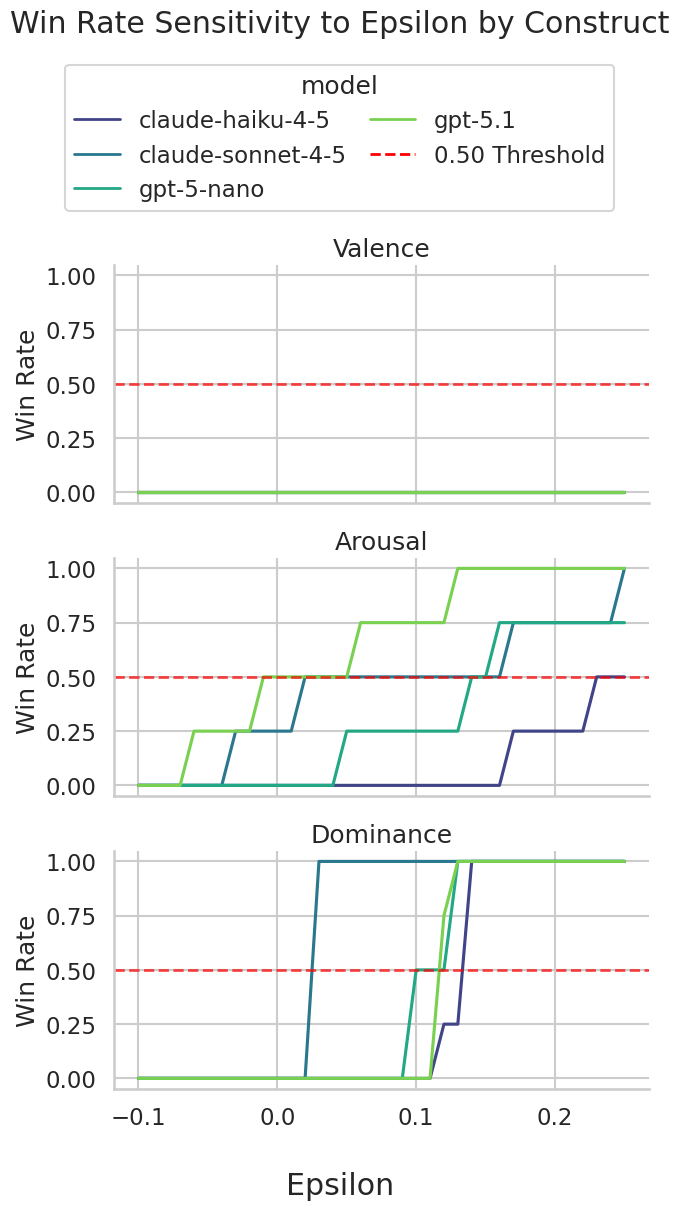

In [8]:
# Plot win rate over epsilon, faceted vertically by construct
from matplotlib.lines import Line2D

winning_rate_data = altest_results[['epsilon', 'winning_rate', 'model', 'construct']].drop_duplicates()
winning_rate_data["construct"] = winning_rate_data["construct"].str.capitalize()
winning_rate_data["construct"] = pd.Categorical(
    winning_rate_data["construct"],
    categories=construct_order,
    ordered=True
)

g2 = sns.relplot(
    data=winning_rate_data,
    x="epsilon",
    y="winning_rate",
    row="construct",
    row_order=construct_order,
    hue="model",
    hue_order=model_order,
    kind="line",
    height=4.2,          # taller facets (was 3.0)
    aspect=1.6,          # less wide (was 2.2)
    palette="viridis",
    legend=False,
)

g2.set_titles("{row_name}")
g2.set_axis_labels("", "Win Rate")

for ax in g2.axes.flat:
    ax.axhline(y=0.5, color="red", linestyle="--", linewidth=2, alpha=0.7)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("")

palette = sns.color_palette("viridis", n_colors=len(model_order))
model_handles = [
    Line2D([0], [0], color=palette[i], lw=2, label=model)
    for i, model in enumerate(model_order)
]
threshold_handle = Line2D([0], [0], color="red", lw=2, linestyle="--", label="0.50 Threshold")

g2.fig.suptitle("Win Rate Sensitivity to Epsilon by Construct", y=0.995)
g2.fig.legend(
    handles=model_handles + [threshold_handle],
    title="model",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,              # narrower legend (was 3)
    frameon=True,
    columnspacing=1.0,
    handlelength=2.0,
)

g2.fig.supxlabel("Epsilon", y=0.05)
plt.tight_layout(rect=[0, 0.04, 1, 0.88])  # more top room for title + legend
plt.show()

## IRRs

In [ ]:
irrs = []
for construct in ['valence', 'arousal', 'dominance']:
    if construct == 'valence':
        irr = validation_valence.irr()
        irr['construct'] = 'valence'
    elif construct == 'dominance':
        irr = validation_dominance.irr()
        irr['construct'] = 'dominance'
    elif construct == 'arousal':
        irr = validation_arousal.irr()
        irr['construct'] = 'arousal'
    irrs.append(irr)

irrs = pd.concat(irrs, ignore_index=True)
irrs

In [11]:
irrs_human = irrs[irrs['group'] == 'human'].copy()

cols_to_select = ['construct', 'n_items', 'score']
irrs_human = irrs_human[cols_to_select].copy()

irrs_human.rename(columns={'score': 'emopair_irrs'}, inplace=True)
irrs_human['emobank_irrs'] = [0.738, 0.595, 0.570]

# Rearrange columns for better presentation
irrs_human = irrs_human[['construct', 'n_items', 'emobank_irrs', 'emopair_irrs']]

# Round emopair_irrs for better readability to the 1000ths place
irrs_human['emopair_irrs'] = irrs_human['emopair_irrs'].round(3)

# Rename Columns for Presentation
irrs_human.rename(columns={
    'construct': 'Construct',
    'n_items': 'Number of Items',
    'emobank_irrs': 'EmoBank IRR',
    'emopair_irrs': 'EmoPair IRR'
}, inplace=True)

# Capitalize Construct Names
irrs_human['Construct'] = irrs_human['Construct'].str.capitalize()

irrs_human['Improvement'] = (irrs_human['EmoPair IRR'] - irrs_human['EmoBank IRR']).round(3)

irrs_human.to_csv('Results/irrs_comparison.csv', index=False)
irrs_human

,Construct,Number of Items,EmoBank IRR,EmoPair IRR,Improvement
0,Valence,170,0.738,0.929,0.191
3,Arousal,204,0.595,0.896,0.301
6,Dominance,208,0.570,0.865,0.295


# Score Distributions

In [27]:
emopair

,id,split,V,A,D,text,Aro_CGCOT_Breakdown,Aro_Bradley_Terry_Score,Aro_BT_rescaled,Dom_CGCOT_Breakdown,Dom_Bradley_Terry_Score,Dom_BT_rescaled
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,0.214964,-7.692308e-02,Original Text: Remember what she said in my la...,-0.314040,0.173554
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.206263,-2.220446e-16,Original Text: If I wasn't working here.\nProm...,-0.313774,-0.157025
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: You onl...",-0.524366,-7.692308e-02,"Original Text: ..""\nPrompt 1 response: I'd be ...",-0.411762,0.008264
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,-0.417513,-7.692308e-02,Original Text: Goodwill helps people get off o...,0.758803,0.190083
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,0.110363,1.307692e-01,Original Text: Sherry learned through our Futu...,0.273397,0.388430
...,...,...,...,...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,0.477870,3.076923e-01,Original Text: Please let it be a constant rem...,-0.167124,0.008264
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.416795,2.307692e-01,Original Text: That’s why I want to extend my ...,-0.118160,0.504132
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,0.372718,-7.692308e-02,Original Text: And why I’m writing you today t...,-0.166372,0.090909
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",0.582596,2.615385e-01,"Original Text: In fact, I want to urge you to ...",0.419108,0.371901


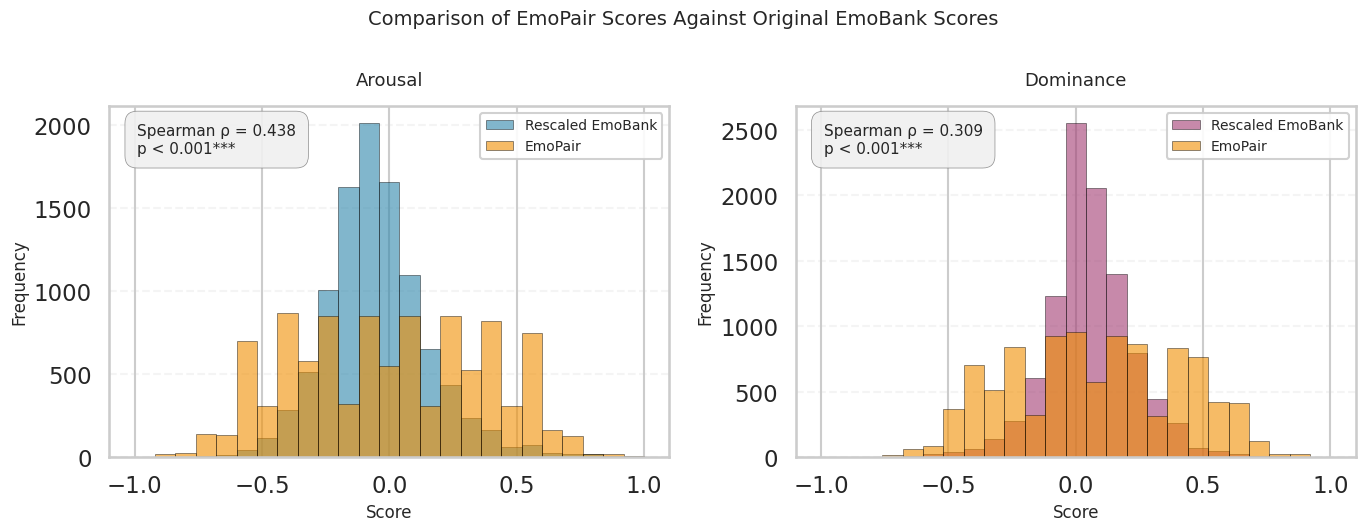

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

df = emopair.copy()

# Calculate Spearman rank correlations
aro_corr, aro_pval = spearmanr(df['Aro_BT_rescaled'], df['Aro_Bradley_Terry_Score'])
dom_corr, dom_pval = spearmanr(df['Dom_BT_rescaled'], df['Dom_Bradley_Terry_Score'])

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.set_style("whitegrid")

# Arousal plot
ax1 = axes[0]
ax1.hist(df['Aro_BT_rescaled'], bins=25, alpha=0.6, label='Rescaled EmoBank', color='#2E86AB', edgecolor='black', linewidth=0.5)
ax1.hist(df['Aro_Bradley_Terry_Score'], bins=25, alpha=0.6, label='EmoPair', color='#F18F01', edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Score', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Arousal', fontsize=13, pad=15)
ax1.grid(True, alpha=0.2, linestyle='--', axis='y')
ax1.legend(loc='upper right', framealpha=0.9, fontsize=10, frameon=True)

# Add correlation text box
textstr_aro = f"Spearman ρ = {aro_corr:.3f}\np < 0.001***" if aro_pval < 0.001 else f"Spearman ρ = {aro_corr:.3f}\np = {aro_pval:.4f}"
ax1.text(0.05, 0.95, textstr_aro, transform=ax1.transAxes, fontsize=11,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='#F0F0F0', alpha=0.9, pad=0.8, edgecolor='gray', linewidth=0.5))

# Dominance plot
ax2 = axes[1]
ax2.hist(df['Dom_BT_rescaled'], bins=25, alpha=0.6, label='Rescaled EmoBank', color='#A23B72', edgecolor='black', linewidth=0.5)
ax2.hist(df['Dom_Bradley_Terry_Score'], bins=25, alpha=0.6, label='EmoPair', color='#F18F01', edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Score', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)
ax2.set_title('Dominance', fontsize=13, pad=15)
ax2.grid(True, alpha=0.2, linestyle='--', axis='y')
ax2.legend(loc='upper right', framealpha=0.9, fontsize=10, frameon=True)

# Add correlation text box
textstr_dom = f"Spearman ρ = {dom_corr:.3f}\np < 0.001***" if dom_pval < 0.001 else f"Spearman ρ = {dom_corr:.3f}\np = {dom_pval:.4f}"
ax2.text(0.05, 0.95, textstr_dom, transform=ax2.transAxes, fontsize=11,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='#F0F0F0', alpha=0.9, pad=0.8, edgecolor='gray', linewidth=0.5))

fig.suptitle('Comparison of EmoPair Scores Against Original EmoBank Scores', fontsize=14, y=0.98)

plt.tight_layout()
plt.savefig('Results/visuals/bt_score_validation.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()